# Evaluate one model

This notebook measures how well **one** sentiment model works. The model reads a comment and labels it **negative**, **neutral** or **positive**.

1. Choose a model in the config cell below.
2. Choose **Restart & Run All**. Expect about 5 minutes for BERT on a recent Mac.
3. The results are saved in `results/<model name>/`.

To compare several models, run this notebook once per model, then open [compare_models.ipynb](./compare_models.ipynb).

## 1. Config

**This is the only cell you need to edit.** `MODEL_NAME` can be any [Hugging Face](https://huggingface.co/models) model that works with `AutoModelForSequenceClassification`, once it has been trained with `exec/train_model.py`. Use `show_models()` in the last section to see which models are trained.

In [1]:
MODEL_NAME = "bert-base-cased"   # any trained Hugging Face model, e.g. "roberta-base" or "cardiffnlp/twitter-roberta-base"
MODEL_PATH = None                # None = MODELS_DIR/github-novielli-<MODEL_NAME>. Set it if the model was saved elsewhere.

# Folders, relative to the sentiment_classifier folder
SPLITS_DIR = "../rawdata/kaiaulu/sentiment/sentiment_classifier/splits"   # train.csv, val.csv, test.csv
MODELS_DIR = "../rawdata/kaiaulu/sentiment/sentiment_classifier/model"    # trained models
RESULTS_DIR = "results"                                                   # where results are saved

## 2. Load the model and the data

The data is divided into three parts:

| Part | What it is for |
|---|---|
| **Training** | The examples the model learned from |
| **Validation** | Examples kept aside, used to choose between models |
| **Test** | Examples kept aside for one final check |

In [ ]:
import sys
import warnings
from pathlib import Path

warnings.filterwarnings("ignore", category=FutureWarning)  # library notices, not about the results

# Find the sentiment_classifier folder, whether Jupyter started there or in notebooks/
REPO = Path.cwd() if (Path.cwd() / "api").exists() else Path.cwd().parent
sys.path.insert(0, str(REPO))

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

from api.labels import LABEL_ORDER
from api.model_registry import REGISTRY, default_model_path, list_trained_models, load_registered_model
from api.sentiment_eval import (
    SPLITS, SPLIT_TITLES, compute_metrics, confusion_matrix, flatten_confusion_matrix,
    flatten_metrics, load_split, plot_confusion_matrix, predict, save_results, split_path,
)

model = load_registered_model(
    MODEL_NAME, REPO / MODELS_DIR, saved_path=None if MODEL_PATH is None else REPO / MODEL_PATH
)
data = {split: load_split(REPO / SPLITS_DIR, split) for split in SPLITS}

print(f"Loaded {MODEL_NAME}. Number of texts per label:")
pd.DataFrame(
    {SPLIT_TITLES[split]: df["polarity"].value_counts().reindex(LABEL_ORDER) for split, df in data.items()}
).rename_axis("Label")

Loaded bert-base-cased. Number of texts per label:


,Training,Validation,Test
Label,,,
negative,1055,123,195
neutral,1029,182,368
positive,1052,143,333


In [3]:
predictions = {}
counts = {}
metrics = {}

def evaluate(split):
    """Predict one part of the data, draw its confusion matrix and print the main scores."""
    y_true = data[split]["polarity"].tolist()
    predictions[split] = predict(model, data[split]["text"])
    counts[split] = confusion_matrix(y_true, predictions[split])
    metrics[split] = compute_metrics(y_true, predictions[split])

    plot_confusion_matrix(counts[split], MODEL_NAME, split)
    plt.show()
    print(f"Accuracy: {metrics[split]['accuracy']:.1%}   Macro F1: {metrics[split]['macro_f1']:.3f}")

### How to read the pictures below

Each picture is a **confusion matrix**. Pick a row: it holds all the texts whose **true** label is that word. Going across, you see which labels the model **predicted** for them. Each row adds up to 100%, and the number of texts is in parentheses.

- **Diagonal** cells (top left to bottom right) are correct predictions. Darker is better.
- All **other** cells are mistakes. Lighter is better.

Two scores are printed under each picture:

- **Accuracy**: the share of texts labeled correctly.
- **Macro F1**: a score from 0 to 1 that gives the three labels equal weight, so a model cannot score well by doing well only on the most common label.

## 3. Training set

**Can the model learn?** If performance is poor on data it was trained on, the model isn't learning the task.

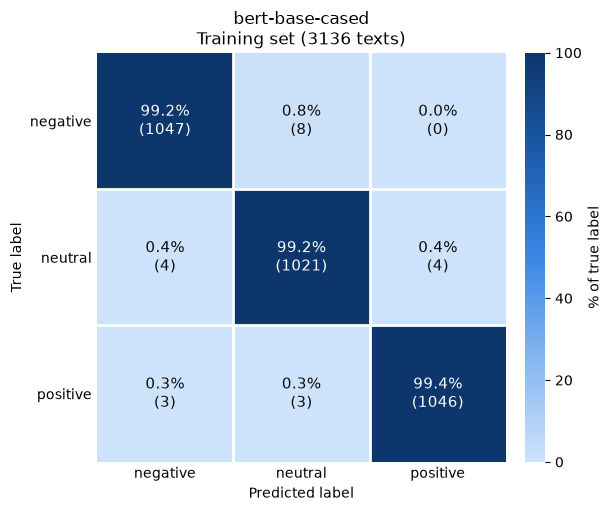

Accuracy: 99.3%   Macro F1: 0.993


In [4]:
evaluate("train")

## 4. Validation set

**Can the model generalize to data it hasn't seen?** A model almost always scores a little lower here than on the training set. A much lower score is called **overfitting**: the model memorized its training examples instead of learning what makes a comment negative, neutral or positive.

Validation scores can be slightly optimistic, because training also used the validation set to decide which version of the model to keep.

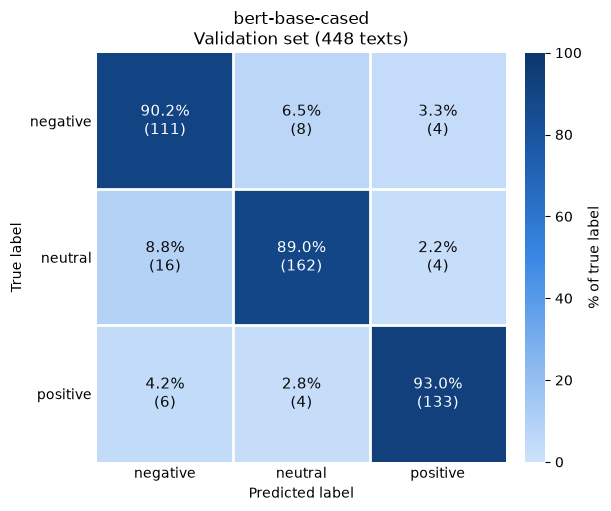

Accuracy: 90.6%   Macro F1: 0.905


In [5]:
evaluate("val")

In [6]:
gap = metrics["train"]["macro_f1"] - metrics["val"]["macro_f1"]
print(f"Training macro F1:   {metrics['train']['macro_f1']:.3f}")
print(f"Validation macro F1: {metrics['val']['macro_f1']:.3f}")
print(f"Gap:                 {gap:+.3f}")

Training macro F1:   0.993
Validation macro F1: 0.905
Gap:                 +0.088


## 5. Test set

**Final, unbiased check. Look at this once you've chosen a model.** If you use the test set to choose, it stops being a fair check. Choose with the validation set instead.

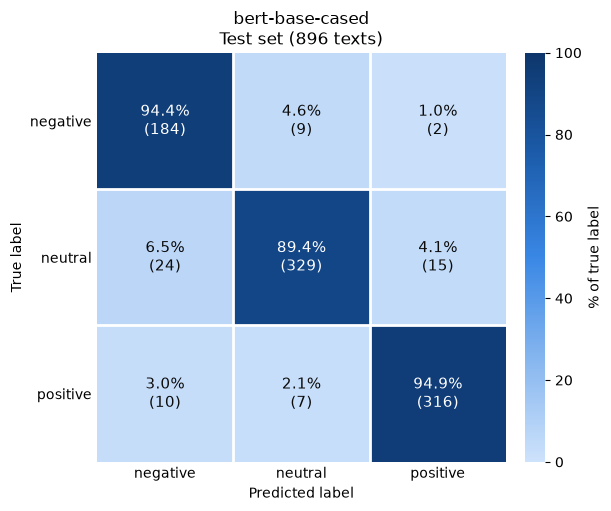

Accuracy: 92.5%   Macro F1: 0.921


In [7]:
evaluate("test")

## 6. All scores

- **Precision** of a label: when the model predicts this label, how often is it right?
- **Recall** of a label: out of all texts that truly have this label, how many did the model find?
- **F1** combines precision and recall into one number.

In [8]:
summary = pd.DataFrame({SPLIT_TITLES[split]: flatten_metrics(metrics[split]) for split in SPLITS}).T
summary = summary.rename(columns={"n": "texts"}).T
summary.style.format(precision=3).format("{:.0f}", subset=pd.IndexSlice[["texts"], :])

,Training,Validation,Test
texts,3136,448,896
accuracy,0.993,0.906,0.925
macro_f1,0.993,0.905,0.921
precision_negative,0.993,0.835,0.844
recall_negative,0.992,0.902,0.944
f1_negative,0.993,0.867,0.891
precision_neutral,0.989,0.931,0.954
recall_neutral,0.992,0.890,0.894
f1_neutral,0.991,0.910,0.923
precision_positive,0.996,0.943,0.949


## 7. Confusion matrices as rows

The same numbers with one column per **true:predicted** pair. For example, `negative:neutral_count` is how many negative texts were predicted as neutral. The comparison notebook reads these rows. They are shown on their side here so that they fit on the screen.

In [9]:
flat = pd.concat([flatten_confusion_matrix(counts[split], MODEL_NAME, split) for split in SPLITS], ignore_index=True)
flat_table = flat.set_index("split").drop(columns="model").T
count_rows = [name for name in flat_table.index if name.endswith("_count")]
percent_rows = [name for name in flat_table.index if name.endswith("_percent")]
(
    flat_table.style.set_caption(MODEL_NAME)
    .format("{:.0f}", subset=pd.IndexSlice[count_rows, :])
    .format("{:.1f}%", subset=pd.IndexSlice[percent_rows, :])
)

split,train,val,test
negative:negative_count,1047,111,184
negative:neutral_count,8,8,9
negative:positive_count,0,4,2
neutral:negative_count,4,16,24
neutral:neutral_count,1021,162,329
neutral:positive_count,4,4,15
positive:negative_count,3,6,10
positive:neutral_count,3,4,7
positive:positive_count,1046,133,316
negative:negative_percent,99.2%,90.2%,94.4%


## 8. Save everything

In [10]:
for split in SPLITS:
    folder = save_results(
        MODEL_NAME, split, data[split]["polarity"].tolist(), predictions[split],
        results_dir=REPO / RESULTS_DIR, data_path=split_path(REPO / SPLITS_DIR, split),
    )

print(f"Saved in {folder.relative_to(REPO)}/:")
for path in sorted(folder.iterdir()):
    print("  ", path.name)

Saved in results/bert-base-cased/:
   test_confusion_flat.csv
   test_confusion_matrix.png
   test_metrics.json
   train_confusion_flat.csv
   train_confusion_matrix.png
   train_metrics.json
   val_confusion_flat.csv
   val_confusion_matrix.png
   val_metrics.json


## How to add a new model

**A model from [Hugging Face](https://huggingface.co/models)**: any model that works with `AutoTokenizer` and `AutoModelForSequenceClassification` can be used by name. No code changes are needed. This example uses `distilbert-base-cased`.

1. Train it. Run this from the `sentiment_classifier` folder:

   ```
   python exec/train_model.py --splits_dir ../rawdata/kaiaulu/sentiment/sentiment_classifier/splits \
       --model_name distilbert-base-cased
   ```

   The model is saved as `MODELS_DIR/github-novielli-distilbert-base-cased`, where this notebook looks for it. A `/` in the name becomes `__`, e.g. `github-novielli-cardiffnlp__twitter-roberta-base`.

2. Set `MODEL_NAME = "distilbert-base-cased"` in the config cell and choose **Restart & Run All**.

If you saved the model somewhere else with `--output`, also set `MODEL_PATH` to that file.

**Any other kind of model**: write a class with `load()` and `predict()` in [api/model_registry.py](../api/model_registry.py), then add it to `REGISTRY`:

```python
class AlwaysNeutral(SentimentModel):
    def predict(self, texts):
        return ["neutral" for text in texts]

# in REGISTRY:
"always-neutral": lambda models_dir: AlwaysNeutral(),
```

In [11]:
def show_models():
    """List the model names that can be used as MODEL_NAME."""
    names = sorted(set(REGISTRY) | set(list_trained_models(REPO / MODELS_DIR)) | {MODEL_NAME})
    for name in names:
        if name in REGISTRY:
            status = "ready (registered)"
        elif default_model_path(name, REPO / MODELS_DIR).exists():
            status = "ready"
        else:
            status = "not trained yet"
        print(f"{name:40} {status}")
    print("\nAny other Hugging Face model can be used too, after training it with exec/train_model.py.")

show_models()

bert-base-cased                          ready

Any other Hugging Face model can be used too, after training it with exec/train_model.py.
